In [1]:
import pandas as pd
import scipy.stats as stats
from scipy.stats import mannwhitneyu, ttest_ind, shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
import numpy as np


df = pd.read_csv('C:/Users/aytimashkov/Desktop/conv_tDCS/conv_tdcs_data_AT.csv', sep=';')

In [2]:
df

,Participant,Group,Correct,False,no_button
0,1,1,568,260,229
1,2,1,414,382,158
2,4,1,450,351,211
3,5,1,457,365,185
4,10,1,561,267,220
5,11,1,516,304,201
6,13,1,486,322,192
7,14,1,314,360,169
8,19,1,582,248,215
9,20,1,208,420,152


In [3]:
print(df['Correct'].tolist())
print(df['False'].tolist())
print(df['no_button'].tolist())

[568, 414, 450, 457, 561, 516, 486, 314, 582, 208, 521, 208, 433, 169, 545, 595, 592, 584, 513, 301]
[260, 382, 351, 365, 267, 304, 322, 360, 248, 420, 266, 469, 388, 529, 284, 225, 216, 219, 316, 522]
[229, 158, 211, 185, 220, 201, 192, 169, 215, 152, 214, 151, 174, 144, 222, 254, 239, 257, 193, 136]


In [4]:
correct_1 = [568, 414, 450, 457, 561, 516, 486, 314, 582, 208]
correct_2 = [521, 208, 433, 169, 545, 595, 592, 584, 513, 301]
false_1 = [260, 382, 351, 365, 267, 304, 322, 360, 248, 420]
false_2 = [266, 469, 388, 529, 284, 225, 216, 219, 316, 522]
no_button_1 = [229, 158, 211, 185, 220, 201, 192, 169, 215, 152]
no_button_2 = [214, 151, 174, 144, 222, 254, 239, 257, 193, 136]

In [5]:
data = correct_1, correct_2, false_1, false_2, no_button_1, no_button_2 

In [6]:
data

([568, 414, 450, 457, 561, 516, 486, 314, 582, 208],
 [521, 208, 433, 169, 545, 595, 592, 584, 513, 301],
 [260, 382, 351, 365, 267, 304, 322, 360, 248, 420],
 [266, 469, 388, 529, 284, 225, 216, 219, 316, 522],
 [229, 158, 211, 185, 220, 201, 192, 169, 215, 152],
 [214, 151, 174, 144, 222, 254, 239, 257, 193, 136])

In [7]:
#step 1. Finding significant differences to all data

In [8]:
#step 1.1. Shapiro-Wilk test

In [9]:
print('correct_1:', shapiro(correct_1))
print('correct_2:', shapiro(correct_2))
print('false_1:', shapiro(false_1))
print('false_2:', shapiro(false_2))
print('no_button_1:', shapiro(no_button_1))
print('no_button_2:', shapiro(no_button_2))

correct_1: ShapiroResult(statistic=0.9014487824394626, pvalue=0.22725235383380932)
correct_2: ShapiroResult(statistic=0.8371290501701462, pvalue=0.040761654337670115)
false_1: ShapiroResult(statistic=0.9500156042752835, pvalue=0.668685161295029)
false_2: ShapiroResult(statistic=0.8634656134722754, pvalue=0.08382420329495435)
no_button_1: ShapiroResult(statistic=0.9438437257543579, pvalue=0.5965198622717063)
no_button_2: ShapiroResult(statistic=0.9206496929951983, pvalue=0.36240548864977334)


In [10]:
#Shapiro test showed that correct_2 is no normal - use Mann-Whitney for Correct

In [11]:
#step 1.3. Mann-Whitney for Correct

In [12]:
pg.mwu(correct_1, correct_2)

,U-val,alternative,p-val,RBC,CLES
MWU,45.5,two-sided,0.762282,-0.09,0.455


In [13]:
np.median(correct_1), np.median(correct_2) # median

(471.5, 517.0)

In [14]:
-0.09 * np.sqrt(len(correct_1) + len(correct_2)) # z-statistics

-0.40249223594996214

In [15]:
#step 1.4. T-test for False

In [16]:
pg.homoscedasticity([false_1, false_2], method='levene') # Leven's test for checking dispersions. Dispersions is equal - use Student's t-test

,W,pval,equal_var
levene,4.07007,0.058812,True


In [17]:
pg.ttest(false_1, false_2, correction=False) # Student’s t-test.

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-0.356887,18,two-sided,0.725326,"[-106.75, 75.75]",0.159605,0.416,0.063207


In [18]:
np.mean(false_1), np.mean(false_2) #means

(327.9, 343.4)

In [19]:
np.std(false_1, ddof=1), np.std(false_2, ddof=1)

(57.405864973305064, 124.7684076822156)

In [20]:
# No significant differences

In [21]:
#step 1.5. T-test for No_button

In [22]:
pg.homoscedasticity([no_button_1, no_button_2], method='levene') # Leven's test for checking dispersion. Dispersions is not equal - use Welch’s t-test

,W,pval,equal_var
levene,4.522594,0.047537,False


In [23]:
pg.ttest(no_button_1, no_button_2, correction=True)  # Welch’s t-test. No significant differences

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-0.311118,14.544495,two-sided,0.760126,"[-40.92, 30.52]",0.139136,0.411,0.060019


In [24]:
np.mean(no_button_1), np.mean(no_button_2) #means

(193.2, 198.4)

In [25]:
np.std(no_button_1, ddof=1), np.std(no_button_2, ddof=1) # standart deviation 

(26.757345824194815, 45.58069766907918)

In [26]:
#No any significant differences in all data

In [27]:
# step 2. Finding significant differences excluding outliers after z-score

In [28]:
data = np.array([[ 1.42437019,  0.83124773,  0.99635999,  0.90364196,  1.32458732,
         1.00885383,  0.8893121 , -0.02152106,  1.44728045, -0.52750963],
       [ 1.12683508, -0.63231665,  0.84970961, -0.84495077,  1.22422395,
         1.48657282,  1.54017803,  1.81343267,  1.02680739,  0.07198197],
       [-0.52543434,  0.60389792,  0.14233714,  0.34506373, -0.5195895 ,
        -0.27312626, -0.11768802,  0.29110068, -0.5880529 ,  0.83907336],
       [-0.48745113,  1.2220052 ,  0.4615174 ,  1.34079014, -0.41295343,
        -0.75084526, -0.76855396, -0.66715293, -0.17367365,  1.49658027],
       [-0.7216809 , -0.98755072, -1.06537194, -0.74780673, -0.81440688,
        -0.89597508, -0.91591983, -1.00695918, -0.78914871, -0.88849381],
       [-0.81663891, -1.03728349, -1.3845522 , -0.99673833, -0.80186146,
        -0.57548006, -0.62732833, -0.40890018, -0.92321258, -0.99163215]])


threshold = 3
outliers = np.where(np.abs(data) > threshold)

print("Indexes of outliers  (row, column):", list(zip(outliers[0], outliers[1])))
print("Values of outliers:", data[outliers])

Indexes of outliers  (row, column): []
Values of outliers: []


Text(0.5, 1.0, 'Z-scores distribution')

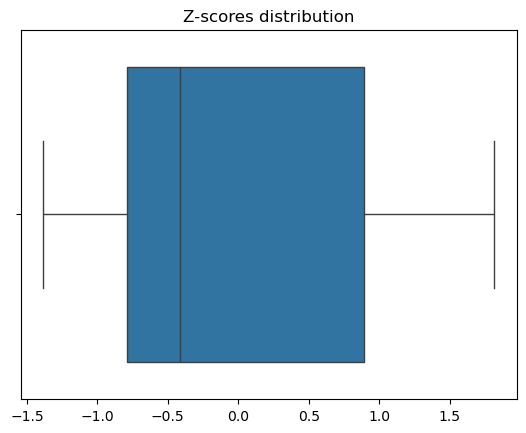

In [29]:
z_scores_flat = data.flatten()
sns.boxplot(x=z_scores_flat).set_title("Z-scores distribution")

In [30]:
# There is no any outliers after z-score

In [31]:
#step 3. Finding significant differences excluding outliers after learning curves analysis

In [32]:
#step 3.1. Excluding outliers by learning curves. We excluded all subjects, who have 400 answers or less (s6,s8,s14,s18,s20)

In [33]:
correct_1_cleaned = [568, 414, 450, 457, 561, 486, 582, 208]
correct_2_cleaned = [521, 208, 433, 545, 595, 592, 513]

false_1_cleaned = [260, 382, 351, 365, 267, 322, 248, 420]
false_2_cleaned = [266, 469, 388, 284, 225, 216, 316]

no_button_1_cleaned = [229, 158, 211, 185, 220, 192, 215, 152]
no_button_2_cleaned = [214, 151, 174, 222, 254, 239, 193]

In [34]:
#step 3.2. Shapiro-Wilk test

In [35]:
print('correct_1_cleaned:', shapiro(correct_1_cleaned))
print('correct_2_cleaned:', shapiro(correct_2_cleaned))
print('false_1_cleaned:', shapiro(false_1_cleaned))
print('false_2_cleaned:', shapiro(false_2_cleaned))
print('no_button_1_cleaned:', shapiro(no_button_1_cleaned))
print('no_button_2_cleaned:', shapiro(no_button_2_cleaned))

correct_1_cleaned: ShapiroResult(statistic=0.8520067350653922, pvalue=0.09982731148438817)
correct_2_cleaned: ShapiroResult(statistic=0.7947343419580413, pvalue=0.03631970128893496)
false_1_cleaned: ShapiroResult(statistic=0.9294045785211084, pvalue=0.5106715221361988)
false_2_cleaned: ShapiroResult(statistic=0.9154701558205148, pvalue=0.43504192226403304)
no_button_1_cleaned: ShapiroResult(statistic=0.9126675286932079, pvalue=0.3732311151632396)
no_button_2_cleaned: ShapiroResult(statistic=0.9761736389328568, pvalue=0.9389895217063776)


In [36]:
#Shapiro test showed that correct_2 is no normal - use Mann-Whitney for Correct

In [37]:
#step 3.3. Mann-Whitney for Correct

In [38]:
pg.mwu(correct_1_cleaned, correct_2_cleaned)

,U-val,alternative,p-val,RBC,CLES
MWU,22.5,two-sided,0.562485,-0.196429,0.401786


In [39]:
np.median(correct_1_cleaned), np.median(correct_2_cleaned) # medians

(471.5, 521.0)

In [40]:
-0.196429 * np.sqrt(len(correct_1_cleaned) + len(correct_2_cleaned)) # z-statistics

-0.7607662457121767

In [41]:
#step 3.4 T-test for False

In [42]:
pg.homoscedasticity([false_1_cleaned, false_2_cleaned], method='levene') # Leven's test for checking dispersion. Dispersions is equal - use Student's t-test

,W,pval,equal_var
levene,0.313548,0.585031,True


In [43]:
pg.ttest(false_1_cleaned, false_2_cleaned, correction=False) # Student’s t-test. No significant differences

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,0.441984,13,two-sided,0.665764,"[-68.94, 104.4]",0.228748,0.467,0.069497


In [44]:
np.mean(false_1_cleaned), np.mean(false_2_cleaned) #means

(326.875, 309.14285714285717)

In [45]:
np.std(false_1_cleaned, ddof=1), np.std(false_2_cleaned, ddof=1) #standart deviation

(63.300727822491446, 91.34992897539396)

In [46]:
#step 3.5. T-test for No_button

In [47]:
pg.homoscedasticity([no_button_1_cleaned, no_button_2_cleaned], method='levene') # Leven's test for checking dispersion. Dispersions is equal - use Student's ttest

,W,pval,equal_var
levene,0.237078,0.634431,True


In [48]:
pg.ttest(no_button_1_cleaned, no_button_2_cleaned, correction=False)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-0.682575,13,two-sided,0.506857,"[-47.75, 24.82]",0.353266,0.511,0.097085


In [49]:
np.mean(no_button_1_cleaned), np.mean(no_button_2_cleaned) #means

(195.25, 206.71428571428572)

In [50]:
np.std(no_button_1_cleaned, ddof=1), np.std(no_button_2_cleaned, ddof=1) #standart deviation

(28.694200509112342, 36.348838980607006)

In [51]:
#No any significant differences after excluding outliers by learning curves. 

In [52]:
import sys
import IPython
import pandas as pd
import scipy
import pingouin
import numpy as np
import matplotlib
import seaborn as sns

print("Python version:", sys.version)
print("Jupyter version:", IPython.__version__)
print("pandas version:", pd.__version__)
print("scipy version:", scipy.__version__)
print("pingouin version:", pingouin.__version__)
print("numpy version:", np.__version__)
print("matplotlib version:", matplotlib.__version__)
print("seaborn version:", sns.__version__)

Python version: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]
Jupyter version: 8.27.0
pandas version: 2.2.2
scipy version: 1.13.1
pingouin version: 0.5.5
numpy version: 1.26.4
matplotlib version: 3.9.2
seaborn version: 0.13.2
